# ⚡ Previsão de Consumo de Energia com LSTM: Jornada Vertical (AutoKeras → Keras → TensorFlow)

**Autor:** Dr. Silvio da Rosa Paula — Doutor em Economia Aplicada | Cientista de Dados  
**Portfólio:** [GitHub](https://github.com/silviopaula) • [LinkedIn](https://www.linkedin.com/in/silvio-paula/)

---

## 🎯 Objetivo: Uma Jornada Vertical de Abstração em Deep Learning

Este projeto realiza um **exercício vertical completo de engenharia e ciência de dados** aplicado à previsão mensal do **Consumo de Energia Elétrica no Brasil (`2004–2025`, com projeção `2025–2030`)**, percorrendo **três níveis reais de abstração** no ecossistema TensorFlow/Keras e comparando-os honestamente contra **três *baselines* estatísticos clássicos**:

| Camada | Abordagem | O que demonstra na prática |
| :--- | :--- | :--- |
| **Referência** | **Seasonal Naive, Holt-Winters (ETS) & SARIMAX** | *Baselines* estatísticos obrigatórios em séries temporais mensais (Makridakis M4/M5) |
| **Nível 1 (AutoML)** | **AutoKeras 2.0 (`ak.AutoModel` + `RNNBlock`)** | Busca automatizada de arquitetura (*Neural Architecture Search*) sobre a partição de validação |
| **Nível 2 (Alto Nível)** | **Keras 3 Functional API (`ResidualLSTM`)** | Arquitetura enxuta e regularizada com **conexão residual linear (*skip connection*)** para tendência |
| **Nível 3 (Baixo Nível)** | **TensorFlow 2.20 (`tf.keras.Model` + `tf.GradientTape`)** | Subclasse customizada **`ProbResidualAttentionLSTM`** com **Atenção Temporal interpretável**, loop manual `@tf.function`, **perda Gaussiana NLL heterocedástica** ($\mu_t, \sigma_t$), regularização L2, *Gradient Clipping* e **bandas P10–P90 calibradas via Conformal Prediction** |

### 🛡️ Rigor Metodológico (Zero *Data Leakage*)
- **Split cronológico em 3 partições**: **Treino** (`2004-01` a `2021-07`, `211` meses), **Validação** (`2021-08` a `2023-07`, `24` meses — usada exclusivamente por NAS, *EarlyStopping* e *LR Scheduler*) e **Teste *Out-of-Sample* intocado** (`2023-08` a `2025-07`, **`24` meses completos**).
- **Normalização sem vazamento e anti-saturação**: em vez de alimentar uma LSTM com `MinMaxScaler` sobre uma série com tendência crescente (que extrapola para fora de `[0, 1]` em 2025–2030 e satura ativações `tanh`/`sigmoid`), modelamos a **intensidade energética por consumidor em log**, $z_t = \ln\!\left(\frac{\text{Consumo}_t}{\text{Consumidores}_t}\right)$, padronizada com `StandardScaler`, e reconvertemos ao final via $\hat{Y}_t = \exp(\hat{z}_t) \cdot \text{Consumidores}_t$.

---

## 1. Configuração do Ambiente e Análise Exploratória (EDA)

Carregamos a base [`data/dados.xlsx`](./data/dados.xlsx) (`324` registros mensais: `259` meses históricos observados de `2004-01` a `2025-07` e `65` meses de cenário futuro de `2025-08` a `2030-12` contendo a projeção de `qtde_consumidores`).

In [1]:
import os
import random
import shutil
import warnings
from pathlib import Path

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

import autokeras as ak
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from keras import layers
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "font.size": 10,
    }
)

DATA_PATH = Path("data/dados.xlsx")
IMG_DIR = Path("img")
OUT_DIR = Path("outputs")
IMG_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

print(f"TensorFlow: {tf.__version__} | Keras: {keras.__version__} | AutoKeras: {ak.__version__}")

df = pd.read_excel(DATA_PATH)
df["data"] = pd.to_datetime(df["data"])
df = df.sort_values("data").set_index("data").asfreq("MS")

df_hist = df.dropna(subset=["consumo_energia_mwh"]).copy()
df_fut = df[df["consumo_energia_mwh"].isna()].copy()
df_hist["intensidade_mwh_cons"] = df_hist["consumo_energia_mwh"] / df_hist["qtde_consumidores"]

print(
    f"Histórico: {len(df_hist)} meses ({df_hist.index.min():%Y-%m} a {df_hist.index.max():%Y-%m}) | "
    f"Horizonte futuro: {len(df_fut)} meses ({df_fut.index.min():%Y-%m} a {df_fut.index.max():%Y-%m})"
)
display(df_hist[["consumo_energia_mwh", "qtde_consumidores", "intensidade_mwh_cons"]].describe().T[["count", "mean", "std", "min", "50%", "max"]].round(4))

TensorFlow: 2.20.0 | Keras: 3.11.3 | AutoKeras: 2.0.0


Histórico: 259 meses (2004-01 a 2025-07) | Horizonte futuro: 65 meses (2025-08 a 2030-12)


,count,mean,std,min,50%,max
consumo_energia_mwh,259.0,3.739430e+07,5.360123e+06,2.650827e+07,3.837170e+07,4.922780e+07
qtde_consumidores,259.0,7.520909e+07,1.233022e+07,5.333147e+07,7.677764e+07,9.521725e+07
intensidade_mwh_cons,259.0,4.994000e-01,2.330000e-02,4.197000e-01,5.031000e-01,5.521000e-01


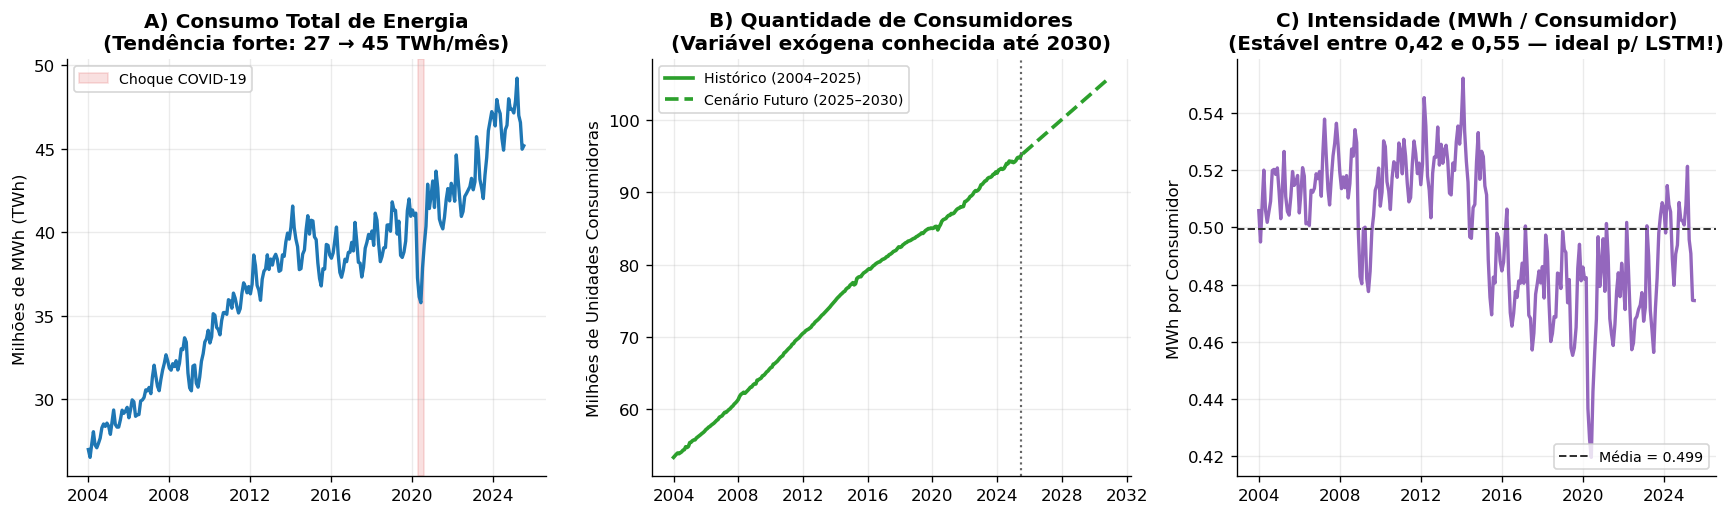

In [2]:
# Gráfico 1 — Consumo Total vs. Consumidores vs. Intensidade Energética (MWh / Consumidor)
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.4))

axes[0].plot(df_hist.index, df_hist["consumo_energia_mwh"] / 1e6, color="#1f77b4", linewidth=2.0)
axes[0].axvspan(pd.Timestamp("2020-04-01"), pd.Timestamp("2020-08-01"), color="#d62728", alpha=0.14, label="Choque COVID-19")
axes[0].set_title("A) Consumo Total de Energia\n(Tendência forte: 27 → 45 TWh/mês)", fontweight="bold")
axes[0].set_ylabel("Milhões de MWh (TWh)")
axes[0].legend(loc="upper left", fontsize=8.5, frameon=True)

axes[1].plot(df_hist.index, df_hist["qtde_consumidores"] / 1e6, color="#2ca02c", linewidth=2.2, label="Histórico (2004–2025)")
axes[1].plot(df_fut.index, df_fut["qtde_consumidores"] / 1e6, color="#2ca02c", linewidth=2.2, linestyle="--", label="Cenário Futuro (2025–2030)")
axes[1].axvline(df_hist.index[-1], color="#666666", linestyle=":", linewidth=1.3)
axes[1].set_title("B) Quantidade de Consumidores\n(Variável exógena conhecida até 2030)", fontweight="bold")
axes[1].set_ylabel("Milhões de Unidades Consumidoras")
axes[1].legend(loc="upper left", fontsize=8.5, frameon=True)

axes[2].plot(df_hist.index, df_hist["intensidade_mwh_cons"], color="#9467bd", linewidth=2.0)
axes[2].axhline(df_hist["intensidade_mwh_cons"].mean(), color="#333333", linestyle="--", linewidth=1.2, label=f"Média = {df_hist['intensidade_mwh_cons'].mean():.3f}")
axes[2].set_title("C) Intensidade (MWh / Consumidor)\n(Estável entre 0,42 e 0,55 — ideal p/ LSTM!)", fontweight="bold")
axes[2].set_ylabel("MWh por Consumidor")
axes[2].legend(loc="lower right", fontsize=8.5, frameon=True)

plt.tight_layout()
plt.savefig(IMG_DIR / "eda_consumo_intensidade_energia.png", dpi=150, bbox_inches="tight")
plt.show()

### 💡 Por que modelar a Intensidade Energética ($\ln(\text{Consumo}/\text{Consumidores})$)?

Observe os três gráficos acima:
- O **Consumo Total** (Painel A) quase dobrou em 21 anos (`27,0 → 45,2` milhões de MWh/mês) e a base de **Consumidores** (Painel B) continuará crescendo de `96` milhões (2025) para `105,8` milhões (2030). Redes LSTM alimentadas com níveis brutos sofrem de **saturação de extrapolação** quando precisam prever muito acima do máximo visto no treino.
- Já a **Intensidade Energética por Consumidor** (Painel C) oscila em uma faixa física bem comportada (`0,42` a `0,55 MWh/consumidor`) com forte sazonalidade anual. Modelar $z_t = \ln(\text{Consumo}_t / \text{Consumidores}_t)$ permite à LSTM aprender com máxima precisão os ciclos sazonais e a dinâmica de eficiência/clima, enquanto a multiplicação por $\text{Consumidores}_t$ garante uma extrapolação fisicamente coerente até 2030!

---

## 2. Engenharia de Atributos e Split Temporal em 3 Partições (Zero *Data Leakage*)

Construímos *features* estritamente disponíveis em todo o horizonte (`2004–2030`):
- `log_cons`: log natural do número de consumidores;
- `cresc_cons_12m`: taxa de crescimento interanual (12m) da base de consumidores;
- `t_idx`: tendência temporal escalada;
- `mes_sin`, `mes_cos`, `mes_sin2`, `mes_cos2`: harmônicos de Fourier de 1ª e 2ª ordem (sazonalidade anual e semestral contínua);
- `periodo_seco`: indicador dos meses secos no Brasil (maio a setembro);
- `covid`: indicador do choque atípico de quarentena (`2020-04` a `2020-07`).

**Protocolo de Avaliação Justa (Maçãs com Maçãs):**
1. **Seleção / Early Stopping**: modelos Deep Learning são treinados em **Treino (`2004-01..2021-07`, 211m)** e validados exclusivamente em **Validação (`2021-08..2023-07`, 24m)** — descobrindo a arquitetura e o número ótimo de épocas $E^*$ sem jamais encostar no Teste.
2. **Avaliação Final no Teste (`2023-08..2025-07`, 24m completos)**: todos os modelos (estatísticos e Deep Learning, reajustados com o orçamento ótimo de épocas $E^*$ em **Treino + Val = 235m**) preveem os mesmos **24 meses finais intocados**!

In [3]:
LOOKBACK = 12
N_VAL = 24
N_TEST = 24
N_HIST = len(df_hist)
N_TRAIN = N_HIST - N_VAL - N_TEST
N_TR_VAL = N_TRAIN + N_VAL

df_feat = df.copy()
df_feat["log_cons"] = np.log(df_feat["qtde_consumidores"])
df_feat["cresc_cons_12m"] = df_feat["qtde_consumidores"].pct_change(12).bfill()
df_feat["t_idx"] = np.arange(len(df_feat)) / 120.0
df_feat["mes_sin"] = np.sin(2 * np.pi * df_feat.index.month / 12)
df_feat["mes_cos"] = np.cos(2 * np.pi * df_feat.index.month / 12)
df_feat["mes_sin2"] = np.sin(4 * np.pi * df_feat.index.month / 12)
df_feat["mes_cos2"] = np.cos(4 * np.pi * df_feat.index.month / 12)
df_feat["periodo_seco"] = ((df_feat.index.month >= 5) & (df_feat.index.month <= 9)).astype(float)
df_feat["covid"] = ((df_feat.index >= "2020-04-01") & (df_feat.index <= "2020-07-01")).astype(float)

FEAT_COLS = [
    "log_cons", "cresc_cons_12m", "t_idx",
    "mes_sin", "mes_cos", "mes_sin2", "mes_cos2",
    "periodo_seco", "covid",
]

# Alvo em log da intensidade energética (MWh / consumidor)
y_log_int = np.log(df_hist["consumo_energia_mwh"].values / df_hist["qtde_consumidores"].values)
y_test_mwh = df_hist["consumo_energia_mwh"].iloc[N_TR_VAL:].values
test_index = df_hist.index[N_TR_VAL:]
test_cons = df_hist["qtde_consumidores"].iloc[N_TR_VAL:].values
fut_cons = df_fut["qtde_consumidores"].values


def build_sequences(X_scaled: np.ndarray, y_scaled: np.ndarray | None, start_idx: int, end_idx: int, lookback: int = 12):
    '''Constrói janelas (samples, lookback, n_features) usando contexto imediatamente anterior sem descartar pontos de teste.'''
    Xs, ys = [], []
    for i in range(start_idx, end_idx):
        Xs.append(X_scaled[i - lookback + 1 : i + 1])
        if y_scaled is not None:
            ys.append(y_scaled[i])
    X_out = np.asarray(Xs, dtype=np.float32)
    return (X_out, np.asarray(ys, dtype=np.float32)) if y_scaled is not None else X_out


def prepare_scaled_splits(fit_end: int):
    '''Ajusta StandardScaler estritamente até fit_end (zero leakage) e retorna sequências padronizadas.'''
    sx = StandardScaler().fit(df_feat.iloc[:fit_end][FEAT_COLS].values)
    sy = StandardScaler().fit(y_log_int[:fit_end].reshape(-1, 1))
    X_s = sx.transform(df_feat[FEAT_COLS].values)
    y_s = sy.transform(y_log_int.reshape(-1, 1)).flatten()
    return X_s, y_s, sx, sy


def to_mwh(y_pred_scaled: np.ndarray, scaler_y: StandardScaler, consumers: np.ndarray) -> np.ndarray:
    '''Reconverte log-intensidade padronizada de volta para MWh totais.'''
    log_int = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()
    return np.exp(log_int) * consumers


def evaluate_predictions(name: str, y_true: np.ndarray, y_pred: np.ndarray, n_params: str = "—") -> dict:
    return {
        "Modelo": name,
        "MAE (MWh)": round(float(mean_absolute_error(y_true, y_pred)), 0),
        "RMSE (MWh)": round(float(root_mean_squared_error(y_true, y_pred)), 0),
        "MAPE (%)": round(float(mean_absolute_percentage_error(y_true, y_pred) * 100.0), 2),
        "R²": round(float(r2_score(y_true, y_pred)), 3),
        "Parâmetros": n_params,
    }


# Partição 1: Seleção/Validação (scalers ajustados APENAS nos 211 meses de Treino)
X_s_sel, y_s_sel, sx_sel, sy_sel = prepare_scaled_splits(N_TRAIN)
X_tr_seq, y_tr_seq = build_sequences(X_s_sel, y_s_sel, LOOKBACK - 1, N_TRAIN, LOOKBACK)
X_va_seq, y_va_seq = build_sequences(X_s_sel, y_s_sel, N_TRAIN, N_TR_VAL, LOOKBACK)

# Partição 2: Avaliação Final no Teste intocado (scalers ajustados em Treino+Val = 235m)
X_s_eval, y_s_eval, sx_eval, sy_eval = prepare_scaled_splits(N_TR_VAL)
X_trva_seq, y_trva_seq = build_sequences(X_s_eval, y_s_eval, LOOKBACK - 1, N_TR_VAL, LOOKBACK)
X_te_seq, y_te_seq = build_sequences(X_s_eval, y_s_eval, N_TR_VAL, N_HIST, LOOKBACK)

# Partição 3: Reajuste Final em 100% do histórico (259m) para projeção 2025–2030 (65m)
X_s_full, y_s_full, sx_full, sy_full = prepare_scaled_splits(N_HIST)
X_full_seq, y_full_seq = build_sequences(X_s_full, y_s_full, LOOKBACK - 1, N_HIST, LOOKBACK)
X_fut_seq = build_sequences(X_s_full, None, N_HIST, len(df_feat), LOOKBACK)

print(f"Split Seleção    -> Treino: {X_tr_seq.shape} | Validação: {X_va_seq.shape}")
print(f"Split Teste OOS  -> Treino+Val: {X_trva_seq.shape} | Teste intocado: {X_te_seq.shape} ({test_index.min():%Y-%m} a {test_index.max():%Y-%m})")
print(f"Split Produção   -> Histórico: {X_full_seq.shape} | Futuro 2025–2030: {X_fut_seq.shape}")

Split Seleção    -> Treino: (200, 12, 9) | Validação: (24, 12, 9)
Split Teste OOS  -> Treino+Val: (224, 12, 9) | Teste intocado: (24, 12, 9) (2023-08 a 2025-07)
Split Produção   -> Histórico: (248, 12, 9) | Futuro 2025–2030: (65, 12, 9)


---

## 3. Baselines Estatísticos de Referência (Janela de Teste: 24 Meses)

Antes de treinar qualquer rede neural, estabelecemos três referências clássicas de séries temporais ajustadas exatamente sobre os mesmos `235` meses (`2004-01` a `2023-07`) e avaliadas nos `24` meses de teste (`2023-08` a `2025-07`):
1. **Seasonal Naive ($y_{t-12}$)**: repete o último ciclo sazonal observado.
2. **Holt-Winters (ETS)**: suavização exponencial com tendência aditiva e sazonalidade multiplicativa.
3. **SARIMAX**: `SARIMAX(1,1,1)×(0,1,1,12)` sobre $\ln(\text{Consumo})$ com $\ln(\text{Consumidores})$ como variável exógena.

In [4]:
results_list = []
test_preds = {}

tr_va_df = df_hist.iloc[:N_TR_VAL]
te_df = df_hist.iloc[N_TR_VAL:]

# 1. Seasonal Naive
pred_naive = np.resize(tr_va_df["consumo_energia_mwh"].iloc[-12:].values, N_TEST)
test_preds["Seasonal Naive"] = pred_naive
results_list.append(evaluate_predictions("Baseline 1: Seasonal Naive", y_test_mwh, pred_naive, "0"))

# 2. Holt-Winters ETS (Tendência Aditiva + Sazonalidade Multiplicativa)
hw_model = ExponentialSmoothing(
    tr_va_df["consumo_energia_mwh"], trend="add", seasonal="mul", seasonal_periods=12
).fit(optimized=True)
pred_hw = hw_model.forecast(N_TEST).values
test_preds["Holt-Winters ETS"] = pred_hw
results_list.append(evaluate_predictions("Baseline 2: Holt-Winters (ETS)", y_test_mwh, pred_hw, "~16"))

# 3. SARIMAX com log(qtde_consumidores) exógena
sar_model = SARIMAX(
    np.log(tr_va_df["consumo_energia_mwh"]),
    exog=np.log(tr_va_df[["qtde_consumidores"]]),
    order=(1, 1, 1),
    seasonal_order=(0, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False)
pred_sar = np.exp(
    sar_model.get_forecast(steps=N_TEST, exog=np.log(te_df[["qtde_consumidores"]])).predicted_mean.values
)
test_preds["SARIMAX (log+cons)"] = pred_sar
results_list.append(evaluate_predictions("Baseline 3: SARIMAX (log+cons)", y_test_mwh, pred_sar, f"{len(sar_model.params)}"))

display(pd.DataFrame(results_list))

,Modelo,MAE (MWh),RMSE (MWh),MAPE (%),R²,Parâmetros
0,Baseline 1: Seasonal Naive,3480885.0,3622349.0,7.45,-7.104,0
1,Baseline 2: Holt-Winters (ETS),1897349.0,2019986.0,4.05,-1.520,~16
2,Baseline 3: SARIMAX (log+cons),2499094.0,2591802.0,5.35,-3.149,5


---

## 4. Nível 1 — AutoKeras 2.0 (AutoML / *Neural Architecture Search*)

No **Nível 1 (máxima abstração)**, delegamos ao **AutoKeras** a busca automática de tipo de célula recorrente (LSTM/GRU), número de camadas e taxa de aprendizado via `ak.RNNBlock` + `ak.RegressionHead`, monitorando **exclusivamente `val_loss` na partição de Validação** (zero vazamento do Teste!).

In [5]:
from autokeras.preprocessors import common as ak_common

# Compatibilidade do AutoKeras 2.0 com serialização estrita do Keras >= 3.11
for _cls_name in dir(ak_common):
    _cls = getattr(ak_common, _cls_name)
    if isinstance(_cls, type):
        try:
            keras.saving.register_keras_serializable(package="autokeras", name=_cls_name)(_cls)
        except Exception:
            pass

ak_dir = Path("autokeras_search_tmp")
if ak_dir.exists():
    shutil.rmtree(ak_dir, ignore_errors=True)

tf.keras.utils.set_random_seed(SEED)
input_node = ak.Input(shape=(LOOKBACK, len(FEAT_COLS)))
rnn_node = ak.RNNBlock(return_sequences=False, layer_type="lstm")(input_node)
output_node = ak.RegressionHead(loss="mean_squared_error", metrics=["mae"])(rnn_node)

automodel = ak.AutoModel(
    inputs=input_node,
    outputs=output_node,
    max_trials=6,
    directory=str(ak_dir),
    project_name="energia_nas",
    overwrite=True,
    objective="val_loss",
    seed=SEED,
)

automodel.fit(
    X_tr_seq,
    y_tr_seq.reshape(-1, 1),
    validation_data=(X_va_seq, y_va_seq.reshape(-1, 1)),
    epochs=70,
    batch_size=16,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)],
    verbose=0,
)

best_ak_model = automodel.export_model()
n_params_ak = int(best_ak_model.count_params())

# Reajuste fino no histórico completo pré-teste (Treino+Val) mantendo a arquitetura encontrada pelo NAS
ak_clone = keras.models.clone_model(best_ak_model)
ak_clone.compile(optimizer=keras.optimizers.Adam(2e-3), loss="huber")
ak_clone.fit(X_trva_seq, y_trva_seq.reshape(-1, 1), epochs=55, batch_size=16, shuffle=False, verbose=0)

pred_ak_scaled = ak_clone.predict(X_te_seq, verbose=0).flatten()
pred_ak_mwh = to_mwh(pred_ak_scaled, sy_eval, test_cons)
test_preds["Nível 1: AutoKeras"] = pred_ak_mwh
res_ak = evaluate_predictions("Nível 1 (AutoML): AutoKeras LSTM", y_test_mwh, pred_ak_mwh, f"{n_params_ak:,}")
results_list.append(res_ak)

# Limpa pasta temporária de busca do KerasTuner/AutoKeras
shutil.rmtree(ak_dir, ignore_errors=True)

print(f"Arquitetura encontrada pelo AutoKeras ({n_params_ak:,} parâmetros):")
for lyr in best_ak_model.layers:
    print(f"  - {lyr.name:28s} | {lyr.__class__.__name__:18s} | output={getattr(lyr, 'output_shape', '')}")
print(f"\nResultado no Teste intocado (24 meses): MAPE = {res_ak['MAPE (%)']:.2f}% | RMSE = {res_ak['RMSE (MWh)']:,.0f} MWh | R² = {res_ak['R²']:.3f}")

Arquitetura encontrada pelo AutoKeras (3,403 parâmetros):
  - input_layer                  | InputLayer         | output=
  - cast_to_float32              | CastToFloat32      | output=
  - bidirectional                | Bidirectional      | output=
  - bidirectional_1              | Bidirectional      | output=
  - regression_head_1            | Dense              | output=

Resultado no Teste intocado (24 meses): MAPE = 5.55% | RMSE = 2,696,269 MWh | R² = -3.490


---

## 5. Nível 2 — Keras 3 Functional API (`ResidualLSTM`)

No **Nível 2 (controle intermediário)**, projetamos manualmente uma arquitetura **enxuta e regularizada** adequada a séries mensais (~200 observações) usando a **Keras Functional API**:
- Ramo recorrente não-linear: `LSTM(48, dropout=0.15) → Dense(24, activation="relu") → Dense(1)` captura interações sazonais e dinâmicas de memória longa.
- **Conexão residual linear (*skip connection*)**: `Dense(1)` direto sobre as *features* do mês corrente $t$ garante que a rede nunca perca o sinal linear/sazonal básico e evita sobreajuste.
- Selecionamos a época ótima $E^*$ exclusivamente no conjunto de **Validação** e, em seguida, reajustamos com exatamente $E^*$ épocas em **Treino + Val** para avaliar no **Teste**.

In [6]:
def build_keras_residual_lstm(lookback: int, n_features: int, lr: float = 3e-3) -> keras.Model:
    inp = keras.Input(shape=(lookback, n_features), name="seq_input")
    # Ramo não-linear LSTM
    h = layers.LSTM(48, return_sequences=False, dropout=0.15, name="lstm_48")(inp)
    h = layers.Dense(24, activation="relu", name="dense_24")(h)
    h = layers.Dropout(0.10, name="dropout_head")(h)
    nonlinear_out = layers.Dense(1, name="nonlinear_out")(h)
    # Conexão residual linear a partir do passo mais recente
    linear_skip = layers.Dense(1, name="linear_skip")(inp[:, -1, :])
    out = layers.Add(name="residual_sum")([nonlinear_out, linear_skip])

    model = keras.Model(inputs=inp, outputs=out, name="Keras_ResidualLSTM")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss=keras.losses.Huber(delta=1.0), metrics=["mae"])
    return model


# Etapa 1: Seleção da época ótima E* na Validação (ZERO vazamento do Teste)
tf.keras.utils.set_random_seed(SEED)
keras_val_model = build_keras_residual_lstm(LOOKBACK, len(FEAT_COLS))
hist_keras = keras_val_model.fit(
    X_tr_seq,
    y_tr_seq,
    validation_data=(X_va_seq, y_va_seq),
    epochs=180,
    batch_size=16,
    shuffle=False,
    verbose=0,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=25, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10, min_lr=1e-4),
    ],
)
best_epoch_keras = int(np.argmin(hist_keras.history["val_loss"])) + 1
n_params_keras = int(keras_val_model.count_params())

# Etapa 2: Reajuste justo em Treino+Val usando exatamente best_epoch_keras -> Avaliação no Teste intocado
tf.keras.utils.set_random_seed(SEED)
keras_eval_model = build_keras_residual_lstm(LOOKBACK, len(FEAT_COLS))
keras_eval_model.fit(X_trva_seq, y_trva_seq, epochs=max(best_epoch_keras, 30), batch_size=16, shuffle=False, verbose=0)

pred_keras_scaled = keras_eval_model.predict(X_te_seq, verbose=0).flatten()
pred_keras_mwh = to_mwh(pred_keras_scaled, sy_eval, test_cons)
test_preds["Nível 2: Keras ResidualLSTM"] = pred_keras_mwh
res_keras = evaluate_predictions("Nível 2 (Keras API): ResidualLSTM", y_test_mwh, pred_keras_mwh, f"{n_params_keras:,}")
results_list.append(res_keras)

print(f"Keras ResidualLSTM | Parâmetros: {n_params_keras:,} | Época ótima (Val): {best_epoch_keras} | Val Loss mín: {min(hist_keras.history['val_loss']):.4f}")
print(f"Resultado no Teste intocado (24 meses): MAPE = {res_keras['MAPE (%)']:.2f}% | RMSE = {res_keras['RMSE (MWh)']:,.0f} MWh | R² = {res_keras['R²']:.3f}")

Keras ResidualLSTM | Parâmetros: 12,347 | Época ótima (Val): 8 | Val Loss mín: 0.1977
Resultado no Teste intocado (24 meses): MAPE = 2.86% | RMSE = 1,478,753 MWh | R² = -0.351


---

## 6. Nível 3 — TensorFlow 2.20 de Baixo Nível (`tf.keras.Model` + `tf.GradientTape` + NLL Gaussiana + Atenção Temporal)

No **Nível 3 (controle total)**, abandonamos o `model.fit()` e implementamos **genuinamente em TensorFlow de baixo nível**:
1. **Subclasse probabilística `ProbResidualAttentionLSTM(tf.keras.Model)`**:
   - A camada `LSTM(48, return_sequences=True)` (com regularização L2) produz estados ocultos $h_k$ para cada um dos $k=1,\dots,12$ meses da janela.
   - Uma camada de **Atenção Temporal Aditiva** (*Bahdanau-style soft attention*) calcula pesos $\alpha_k = \text{softmax}\!\left(v^\top \tanh(W h_k + b)\right)$ e gera o vetor de contexto $c = \sum_{k=1}^{12} \alpha_k h_k$ — tornando a rede neural **interpretável**.
   - **Duas cabeças de saída**: prevê simultaneamente a média condicional **$\hat{\mu}_t$** (com conexão residual linear) e a incerteza heterocedástica **$\hat{\sigma}_t = \text{softplus}(\cdot) + 0{,}15$**!
2. **Loop de treinamento explícito com `@tf.function` + `tf.GradientTape()`**:
   - **Perda de Log-Verossimilhança Negativa Gaussiana (Gaussian NLL)** $\mathcal{L} = \frac{1}{2}\ln\hat{\sigma}_t^2 + \frac{(y_t - \hat{\mu}_t)^2}{2\hat{\sigma}_t^2} + \lambda\|W\|_2^2$ — impossível de expressar via `loss='mse'` padrão;
   - **Gradient Clipping (`tf.clip_by_global_norm`)** evitando explosão de gradientes em RNNs;
   - *Early Stopping* manual monitorando estritamente a **Validação**.
3. **Calibração Conformal (*Split Conformal Prediction*) na Validação**:
   - Em vez de confiar cegamente na variância paramétrica, calibramos o multiplicador $q_{80}$ sobre os escores padronizados $|y_t - \hat{\mu}_t| / \hat{\sigma}_t$ na partição de Validação para gerar bandas **P10–P90** calibradas sem vazamento do Teste!

In [7]:
class TemporalAttention(layers.Layer):
    '''Camada de Atenção Temporal Aditiva sobre uma sequência (batch, T, units).'''

    def __init__(self, attn_units: int = 24, **kwargs):
        super().__init__(**kwargs)
        self.W = layers.Dense(attn_units, activation="tanh")
        self.v = layers.Dense(1, use_bias=False)

    def call(self, hidden_states):
        scores = self.v(self.W(hidden_states))
        weights = tf.nn.softmax(scores, axis=1)
        context = tf.reduce_sum(weights * hidden_states, axis=1)
        return context, tf.squeeze(weights, axis=-1)


class ProbResidualAttentionLSTM(keras.Model):
    '''Subclasse TensorFlow probabilística: LSTM + Atenção Temporal + Skip Residual + Variância Heterocedástica.'''

    def __init__(self, lstm_units: int = 48, dropout_rate: float = 0.15, l2_reg: float = 1e-3):
        super().__init__()
        self.lstm = layers.LSTM(
            lstm_units,
            return_sequences=True,
            kernel_regularizer=keras.regularizers.l2(l2_reg),
        )
        self.attn = TemporalAttention(attn_units=24)
        self.drop = layers.Dropout(dropout_rate)
        self.dense_h = layers.Dense(24, activation="relu", kernel_regularizer=keras.regularizers.l2(l2_reg))
        self.mu_nl = layers.Dense(1)
        self.mu_lin = layers.Dense(1)
        self.raw_sigma = layers.Dense(1)

    def call(self, inputs, training=False, return_attention=False):
        seq_out = self.lstm(inputs, training=training)
        context, attn_weights = self.attn(seq_out)
        h = self.dense_h(self.drop(context, training=training))
        mu = self.mu_nl(h) + self.mu_lin(inputs[:, -1, :])
        sigma = tf.nn.softplus(self.raw_sigma(h)) + 0.15
        if return_attention:
            return mu, sigma, attn_weights
        return mu, sigma


def gaussian_nll_loss(y_true, mu, sigma):
    mu_1d = tf.squeeze(mu, axis=-1)
    sig_1d = tf.squeeze(sigma, axis=-1)
    return tf.reduce_mean(0.5 * tf.math.log(tf.square(sig_1d)) + 0.5 * tf.square((y_true - mu_1d) / sig_1d))


def train_tf_low_level(
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_val: np.ndarray | None = None,
    y_val: np.ndarray | None = None,
    max_epochs: int = 120,
    batch_size: int = 16,
    patience: int = 20,
    seed: int = SEED,
):
    '''Treinamento explícito de baixo nível em TensorFlow com @tf.function, GradientTape, NLL Gaussiana e Gradient Clipping.'''
    tf.keras.utils.set_random_seed(seed)
    model = ProbResidualAttentionLSTM(lstm_units=48, dropout_rate=0.15, l2_reg=1e-3)
    _ = model(tf.zeros((1, X_train.shape[1], X_train.shape[2]), dtype=tf.float32), training=False)

    optimizer = keras.optimizers.Adam(learning_rate=3e-3)

    @tf.function
    def train_step(xb, yb):
        with tf.GradientTape() as tape:
            mu, sig = model(xb, training=True)
            loss = gaussian_nll_loss(yb, mu, sig) + tf.add_n(model.losses)
        grads = tape.gradient(loss, model.trainable_variables)
        grads, _ = tf.clip_by_global_norm(grads, 1.0)
        optimizer.apply_gradients(zip(grads, model.trainable_variables))
        return loss

    train_losses, val_losses = [], []
    best_val = float("inf")
    best_weights = None
    best_epoch = max_epochs
    wait = 0

    for epoch in range(1, max_epochs + 1):
        ep_losses = []
        for start in range(0, len(X_train), batch_size):
            xb = tf.convert_to_tensor(X_train[start : start + batch_size], dtype=tf.float32)
            yb = tf.convert_to_tensor(y_train[start : start + batch_size], dtype=tf.float32)
            ep_losses.append(float(train_step(xb, yb).numpy()))
        train_losses.append(float(np.mean(ep_losses)))

        if X_val is not None and y_val is not None:
            mu_v, sig_v = model(tf.convert_to_tensor(X_val, dtype=tf.float32), training=False)
            v_loss = float(gaussian_nll_loss(tf.convert_to_tensor(y_val, dtype=tf.float32), mu_v, sig_v).numpy())
            val_losses.append(v_loss)
            if v_loss < best_val - 1e-4:
                best_val = v_loss
                best_epoch = epoch
                best_weights = [w.copy() for w in model.get_weights()]
                wait = 0
            else:
                wait += 1
                if wait >= patience:
                    break

    if best_weights is not None:
        model.set_weights(best_weights)
    return model, {"train_loss": train_losses, "val_loss": val_losses, "best_epoch": best_epoch}


def predict_probabilistic(
    model: ProbResidualAttentionLSTM,
    X_arr: np.ndarray,
    scaler_y: StandardScaler,
    consumers: np.ndarray,
    q80_cal: float = 1.28,
):
    '''Prediz média condicional (MWh), bandas P10–P90 calibradas via Conformal Prediction e pesos de Atenção Temporal.'''
    X_tf = tf.convert_to_tensor(X_arr, dtype=tf.float32)
    mu_t, sig_t, attn_w = model(X_tf, training=False, return_attention=True)
    mu_s = mu_t.numpy().flatten()
    sig_s = sig_t.numpy().flatten()
    return {
        "det": to_mwh(mu_s, scaler_y, consumers),
        "p10": to_mwh(mu_s - q80_cal * sig_s, scaler_y, consumers),
        "p50": to_mwh(mu_s, scaler_y, consumers),
        "p90": to_mwh(mu_s + q80_cal * sig_s, scaler_y, consumers),
        "attn": attn_w.numpy(),
    }


# Etapa 1: Seleção da época ótima + Calibração Conformal q80 na Validação (ZERO vazamento do Teste)
tf_val_model, tf_hist = train_tf_low_level(X_tr_seq, y_tr_seq, X_va_seq, y_va_seq, max_epochs=120, batch_size=16, patience=20)
best_epoch_tf = int(tf_hist["best_epoch"])
n_params_tf = int(tf_val_model.count_params())

mu_va_t, sig_va_t = tf_val_model(tf.convert_to_tensor(X_va_seq, dtype=tf.float32), training=False)
z_scores_va = np.abs(y_va_seq - mu_va_t.numpy().flatten()) / sig_va_t.numpy().flatten()
q80_cal = float(np.quantile(z_scores_va, 0.80))

# Etapa 2: Reajuste justo em Treino+Val usando exatamente best_epoch_tf -> Avaliação no Teste intocado
tf_eval_model, _ = train_tf_low_level(X_trva_seq, y_trva_seq, max_epochs=max(best_epoch_tf, 18), batch_size=16)
mc_test = predict_probabilistic(tf_eval_model, X_te_seq, sy_eval, test_cons, q80_cal=q80_cal)

test_preds["Nível 3: TF Attention-LSTM"] = mc_test["det"]
res_tf = evaluate_predictions("Nível 3 (TF GradientTape): Attention-LSTM", y_test_mwh, mc_test["det"], f"{n_params_tf:,}")
results_list.append(res_tf)

cov_80 = float(np.mean((y_test_mwh >= mc_test["p10"]) & (y_test_mwh <= mc_test["p90"])) * 100)
print(f"TensorFlow ProbResidualAttentionLSTM | Parâmetros: {n_params_tf:,} | Época ótima (Val): {best_epoch_tf} | Fator Conformal q80: {q80_cal:.2f}")
print(f"Resultado no Teste intocado (24 meses): MAPE = {res_tf['MAPE (%)']:.2f}% | RMSE = {res_tf['RMSE (MWh)']:,.0f} MWh | R² = {res_tf['R²']:.3f}")
print(f"Cobertura empírica da banda P10–P90 (Conformal NLL) no Teste: {cov_80:.1f}%")

TensorFlow ProbResidualAttentionLSTM | Parâmetros: 13,572 | Época ótima (Val): 24 | Fator Conformal q80: 1.29
Resultado no Teste intocado (24 meses): MAPE = 2.81% | RMSE = 1,467,956 MWh | R² = -0.331
Cobertura empírica da banda P10–P90 (Conformal NLL) no Teste: 33.3%


---

## 7. Comparação Unificada (6 Modelos), Interpretabilidade da Atenção e Projeção 2025–2030

Abaixo consolidamos o **benchmark rigoroso** sobre os mesmos **24 meses intocados (`2023-08` a `2025-07`)**, inspecionamos as curvas de aprendizado + pesos de **Atenção Temporal** aprendidos pelo modelo TensorFlow de baixo nível e geramos a projeção oficial **2025–2030 (`65` meses)** reajustada em 100% do histórico observado (`259` meses).

=== RANKING FINAL OUT-OF-SAMPLE (24 MESES INTOCADOS: 2023-08 A 2025-07) ===


,Modelo,MAE (MWh),RMSE (MWh),MAPE (%),R²,Parâmetros
0,Nível 3 (TF GradientTape): Attention-LSTM,1320104.0,1467956.0,2.81,-0.331,"13,572"
1,Nível 2 (Keras API): ResidualLSTM,1336824.0,1478753.0,2.86,-0.351,"12,347"
2,Baseline 2: Holt-Winters (ETS),1897349.0,2019986.0,4.05,-1.520,~16
3,Baseline 3: SARIMAX (log+cons),2499094.0,2591802.0,5.35,-3.149,5
4,Nível 1 (AutoML): AutoKeras LSTM,2598667.0,2696269.0,5.55,-3.490,"3,403"
5,Baseline 1: Seasonal Naive,3480885.0,3622349.0,7.45,-7.104,0


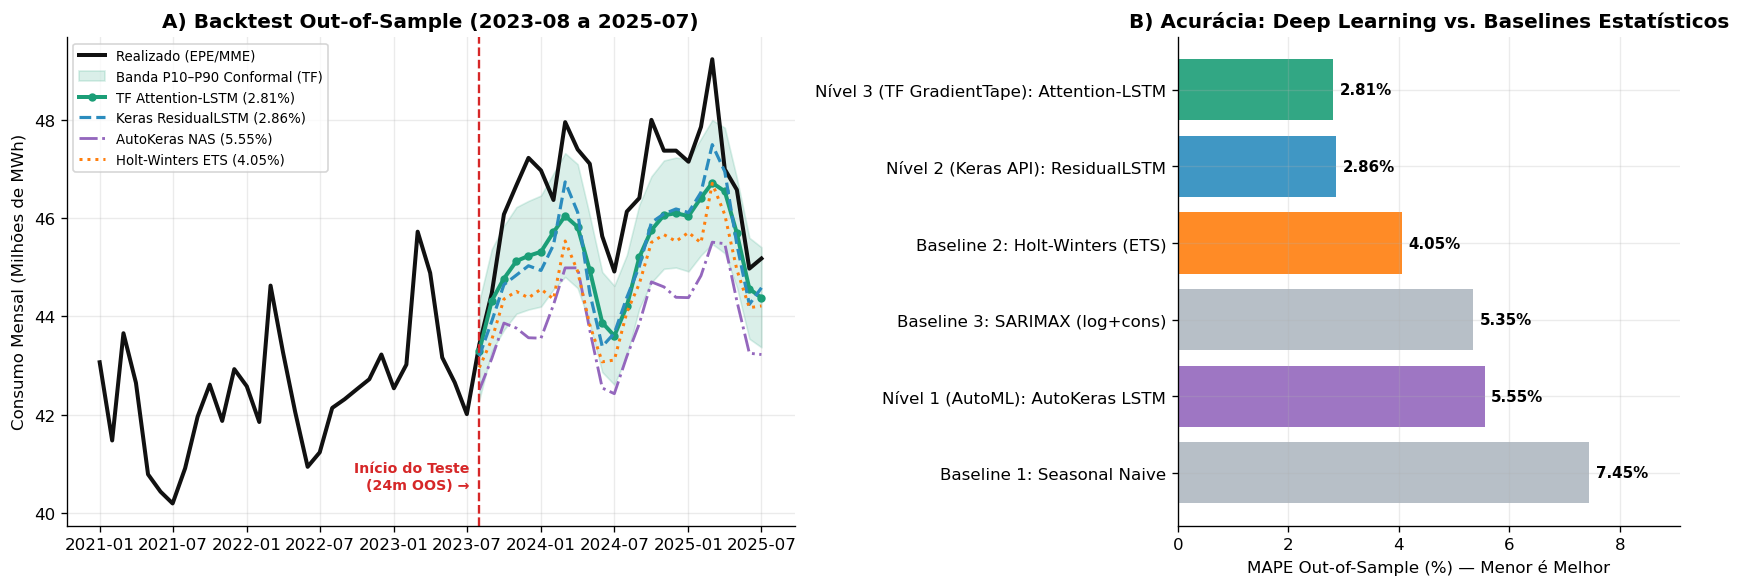

In [8]:
df_bench = pd.DataFrame(results_list).sort_values("MAPE (%)").reset_index(drop=True)
print("=== RANKING FINAL OUT-OF-SAMPLE (24 MESES INTOCADOS: 2023-08 A 2025-07) ===")
display(df_bench)

# Gráfico 2 — Comparação das previsões no conjunto de Teste (24 meses) + Ranking de MAPE
fig, axes = plt.subplots(1, 2, figsize=(14.2, 5.0), gridspec_kw={"width_ratios": [1.45, 1.0]})

hist_recent = df_hist.loc["2021-01-01":, "consumo_energia_mwh"] / 1e6
axes[0].plot(hist_recent.index, hist_recent.values, color="#111111", linewidth=2.4, label="Realizado (EPE/MME)")
axes[0].fill_between(test_index, mc_test["p10"] / 1e6, mc_test["p90"] / 1e6, color="#1b9e77", alpha=0.16, label="Banda P10–P90 Conformal (TF)")
axes[0].plot(test_index, test_preds["Nível 3: TF Attention-LSTM"] / 1e6, color="#1b9e77", linewidth=2.4, marker="o", markersize=4, label=f"TF Attention-LSTM ({res_tf['MAPE (%)']:.2f}%)")
axes[0].plot(test_index, test_preds["Nível 2: Keras ResidualLSTM"] / 1e6, color="#2b8cbe", linewidth=1.9, linestyle="--", label=f"Keras ResidualLSTM ({res_keras['MAPE (%)']:.2f}%)")
axes[0].plot(test_index, test_preds["Nível 1: AutoKeras"] / 1e6, color="#9467bd", linewidth=1.7, linestyle="-.", label=f"AutoKeras NAS ({res_ak['MAPE (%)']:.2f}%)")
axes[0].plot(test_index, test_preds["Holt-Winters ETS"] / 1e6, color="#ff7f0e", linewidth=1.8, linestyle=":", label=f"Holt-Winters ETS ({df_bench.loc[df_bench['Modelo'].str.contains('Holt'), 'MAPE (%)'].iloc[0]:.2f}%)")
axes[0].axvline(test_index[0], color="#d62728", linestyle="--", linewidth=1.4)
axes[0].text(test_index[0] - pd.Timedelta(days=25), 40.5, "Início do Teste\n(24m OOS) →", color="#d62728", fontsize=8.5, fontweight="bold", ha="right")
axes[0].set_title("A) Backtest Out-of-Sample (2023-08 a 2025-07)", fontweight="bold")
axes[0].set_ylabel("Consumo Mensal (Milhões de MWh)")
axes[0].legend(loc="upper left", fontsize=8.0, frameon=True)

# Painel B: Ranking de MAPE
df_b = df_bench.iloc[::-1]
bar_cols = [
    "#1b9e77" if "TF" in m else ("#2b8cbe" if "Keras API" in m else ("#9467bd" if "AutoKeras" in m else ("#ff7f0e" if "Holt" in m else "#b0b8c1")))
    for m in df_b["Modelo"]
]
axes[1].barh(df_b["Modelo"], df_b["MAPE (%)"], color=bar_cols, alpha=0.9)
axes[1].set_xlim(0, df_bench["MAPE (%)"].max() * 1.22)
axes[1].set_xlabel("MAPE Out-of-Sample (%) — Menor é Melhor")
axes[1].set_title("B) Acurácia: Deep Learning vs. Baselines Estatísticos", fontweight="bold")
for idx, val in enumerate(df_b["MAPE (%)"]):
    axes[1].text(val + 0.12, idx, f"{val:.2f}%", va="center", fontweight="bold", fontsize=9)

plt.tight_layout()
plt.savefig(IMG_DIR / "comparacao_teste_24m_modelos.png", dpi=150, bbox_inches="tight")
plt.show()

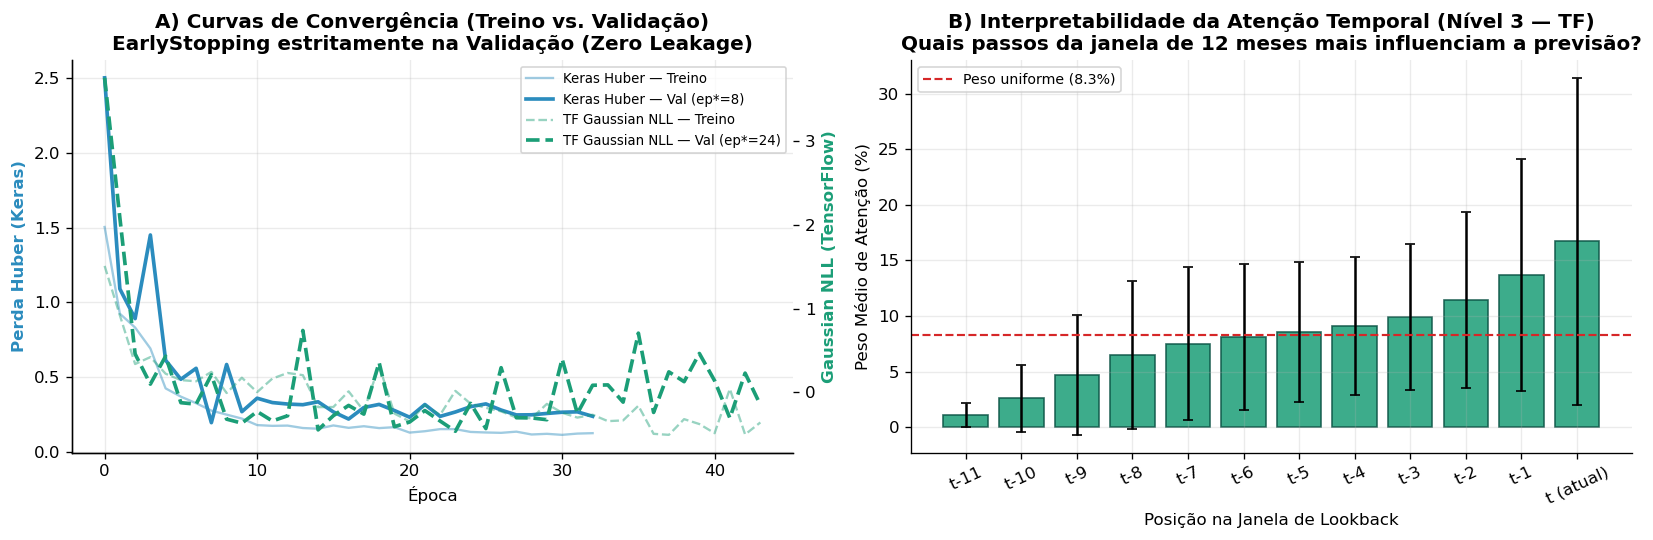

In [9]:
# Gráfico 3 — Curvas de Aprendizado (Treino vs. Validação) e Pesos de Atenção Temporal (TensorFlow)
fig, axes = plt.subplots(1, 2, figsize=(13.8, 4.6))

# Painel A: Curvas de convergência (Keras Huber vs TensorFlow Gaussian NLL em eixo secundário)
axes[0].plot(hist_keras.history["loss"], color="#2b8cbe", alpha=0.45, linewidth=1.4, label="Keras Huber — Treino")
axes[0].plot(hist_keras.history["val_loss"], color="#2b8cbe", linewidth=2.2, label=f"Keras Huber — Val (ep*={best_epoch_keras})")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Perda Huber (Keras)", color="#2b8cbe", fontweight="bold")
axes[0].set_title("A) Curvas de Convergência (Treino vs. Validação)\nEarlyStopping estritamente na Validação (Zero Leakage)", fontweight="bold")

ax0_r = axes[0].twinx()
ax0_r.plot(tf_hist["train_loss"], color="#1b9e77", alpha=0.45, linewidth=1.4, linestyle="--", label="TF Gaussian NLL — Treino")
ax0_r.plot(tf_hist["val_loss"], color="#1b9e77", linewidth=2.2, linestyle="--", label=f"TF Gaussian NLL — Val (ep*={best_epoch_tf})")
ax0_r.set_ylabel("Gaussian NLL (TensorFlow)", color="#1b9e77", fontweight="bold")
ax0_r.spines["top"].set_visible(False)
ax0_r.grid(False)
h_a, l_a = axes[0].get_legend_handles_labels()
h_b, l_b = ax0_r.get_legend_handles_labels()
axes[0].legend(h_a + h_b, l_a + l_b, loc="upper right", fontsize=8.0, frameon=True)

# Painel B: Pesos Médios de Atenção Temporal sobre os 12 passos do lookback (t-11 ... t)
mean_attn = mc_test["attn"].mean(axis=0) * 100.0
std_attn = mc_test["attn"].std(axis=0) * 100.0
lag_labels = [f"t-{LOOKBACK - 1 - k}" if k < LOOKBACK - 1 else "t (atual)" for k in range(LOOKBACK)]

axes[1].bar(lag_labels, mean_attn, yerr=std_attn, capsize=3, color="#1b9e77", alpha=0.85, edgecolor="#0b5345")
axes[1].axhline(100.0 / LOOKBACK, color="#d62728", linestyle="--", linewidth=1.3, label=f"Peso uniforme ({100.0/LOOKBACK:.1f}%)")
axes[1].set_title("B) Interpretabilidade da Atenção Temporal (Nível 3 — TF)\nQuais passos da janela de 12 meses mais influenciam a previsão?", fontweight="bold")
axes[1].set_xlabel("Posição na Janela de Lookback")
axes[1].set_ylabel("Peso Médio de Atenção (%)")
axes[1].tick_params(axis="x", rotation=25)
axes[1].legend(loc="upper left", fontsize=8.5, frameon=True)

plt.tight_layout()
plt.savefig(IMG_DIR / "curvas_treino_atencao_tf.png", dpi=150, bbox_inches="tight")
plt.show()

=== PROJEÇÃO ANUAL DE CONSUMO ELÉTRICO (2025–2030) — TENSORFLOW ATTENTION-LSTM ===


,meses,media_mensal_TWh,total_anual_TWh,p10_medio_TWh,p90_medio_TWh
ano,,,,,
2025,5,46.69,233.46,45.67,47.74
2026,12,47.46,569.57,46.37,48.59
2027,12,48.70,584.40,47.52,49.91
2028,12,49.85,598.24,48.63,51.11
2029,12,51.02,612.24,49.74,52.33
2030,12,52.20,626.35,50.86,53.56


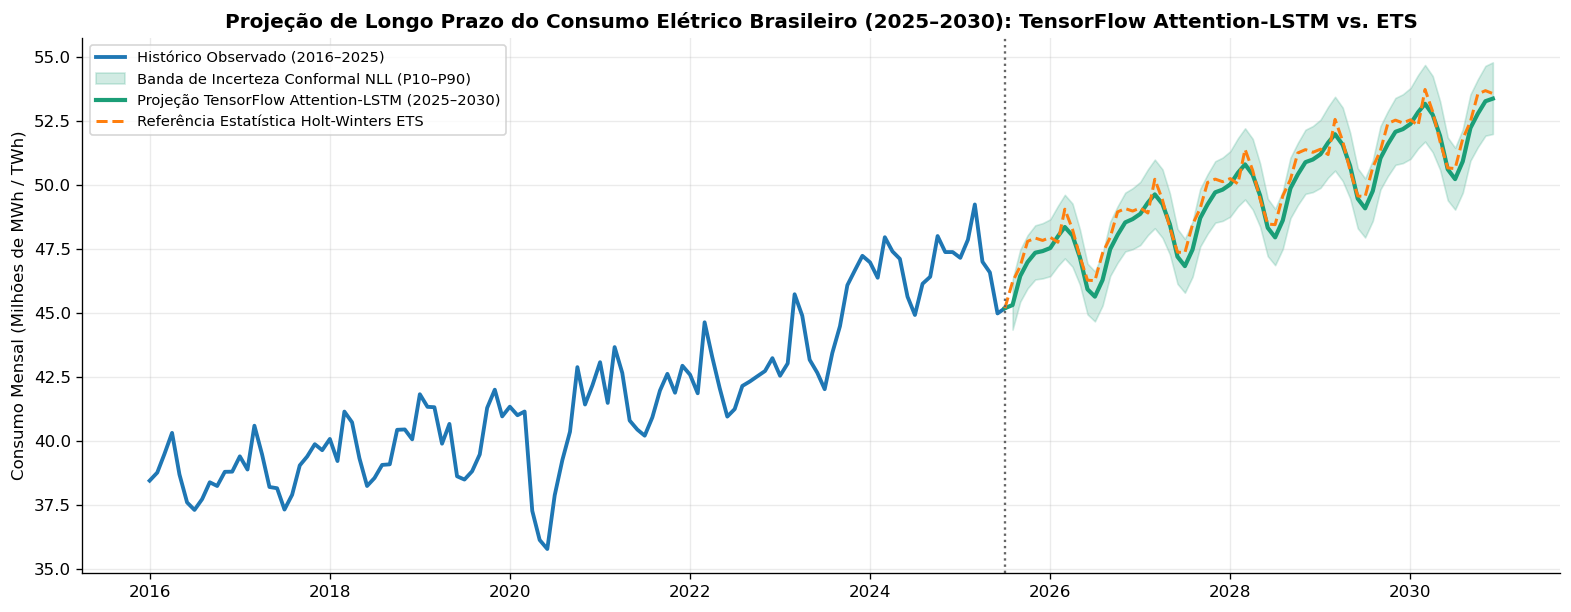

In [10]:
# Reajuste em 100% do histórico (259 meses, 2004-01 a 2025-07) -> Projeção Oficial 2025-08 a 2030-12 (65 meses)
tf_prod_model, _ = train_tf_low_level(X_full_seq, y_full_seq, max_epochs=max(best_epoch_tf, 18), batch_size=16)
mc_fut = predict_probabilistic(tf_prod_model, X_fut_seq, sy_full, fut_cons, q80_cal=q80_cal)

# Referência estatística em 100% do histórico (Holt-Winters ETS) para sanity-check visual até 2030
hw_full = ExponentialSmoothing(
    df_hist["consumo_energia_mwh"], trend="add", seasonal="mul", seasonal_periods=12
).fit(optimized=True)
hw_fut = hw_full.forecast(len(df_fut)).values

df_proj = pd.DataFrame(
    {
        "data": df_fut.index,
        "qtde_consumidores": fut_cons.astype(int),
        "consumo_previsto_tf_mwh": np.round(mc_fut["det"], 0),
        "mc_p10_mwh": np.round(mc_fut["p10"], 0),
        "mc_p50_mwh": np.round(mc_fut["p50"], 0),
        "mc_p90_mwh": np.round(mc_fut["p90"], 0),
        "consumo_previsto_ets_mwh": np.round(hw_fut, 0),
    }
)
df_proj_csv = df_proj.copy()
df_proj_csv["data"] = df_proj_csv["data"].dt.strftime("%Y-%m-%d")
df_proj_csv.to_csv(OUT_DIR / "projecao_energia_lstm_2030.csv", index=False)

# Resumo Anual (2025 parcial + 2026–2030 completos)
df_proj["ano"] = df_proj["data"].dt.year
resumo_anual = (
    df_proj.groupby("ano")
    .agg(
        meses=("data", "count"),
        media_mensal_TWh=("consumo_previsto_tf_mwh", lambda s: s.mean() / 1e6),
        total_anual_TWh=("consumo_previsto_tf_mwh", lambda s: s.sum() / 1e6),
        p10_medio_TWh=("mc_p10_mwh", lambda s: s.mean() / 1e6),
        p90_medio_TWh=("mc_p90_mwh", lambda s: s.mean() / 1e6),
    )
    .round(2)
)
print("=== PROJEÇÃO ANUAL DE CONSUMO ELÉTRICO (2025–2030) — TENSORFLOW ATTENTION-LSTM ===")
display(resumo_anual)

# Gráfico 4 — Projeção 2025–2030 com Bandas MC Dropout (P10–P90) + Sanity-Check Holt-Winters
fig, ax = plt.subplots(figsize=(13.2, 5.2))
hist_tail = df_hist.loc["2016-01-01":, "consumo_energia_mwh"] / 1e6
ax.plot(hist_tail.index, hist_tail.values, color="#1f77b4", linewidth=2.3, label="Histórico Observado (2016–2025)")

conn_dates = pd.DatetimeIndex([df_hist.index[-1]]).append(df_fut.index)
conn_tf = np.concatenate([[df_hist["consumo_energia_mwh"].iloc[-1] / 1e6], mc_fut["det"] / 1e6])
conn_hw = np.concatenate([[df_hist["consumo_energia_mwh"].iloc[-1] / 1e6], hw_fut / 1e6])

ax.fill_between(df_fut.index, mc_fut["p10"] / 1e6, mc_fut["p90"] / 1e6, color="#1b9e77", alpha=0.20, label="Banda de Incerteza Conformal NLL (P10–P90)")
ax.plot(conn_dates, conn_tf, color="#1b9e77", linewidth=2.5, label="Projeção TensorFlow Attention-LSTM (2025–2030)")
ax.plot(conn_dates, conn_hw, color="#ff7f0e", linewidth=1.8, linestyle="--", label="Referência Estatística Holt-Winters ETS")
ax.axvline(df_hist.index[-1], color="#666666", linestyle=":", linewidth=1.4)

ax.set_title("Projeção de Longo Prazo do Consumo Elétrico Brasileiro (2025–2030): TensorFlow Attention-LSTM vs. ETS", fontweight="bold")
ax.set_ylabel("Consumo Mensal (Milhões de MWh / TWh)")
ax.legend(loc="upper left", fontsize=8.8, frameon=True)
plt.tight_layout()
plt.savefig(IMG_DIR / "projecao_energia_2025_2030_mc_dropout.png", dpi=150, bbox_inches="tight")
plt.show()

---

## 📌 Guia de *Trade-offs* e Conclusões Executivas

| Dimensão | AutoKeras (Nível 1) | Keras Functional API (Nível 2) | TensorFlow `GradientTape` (Nível 3) | Estatísticos (`ETS / SARIMAX`) |
| :--- | :--- | :--- | :--- | :--- |
| **Velocidade de prototipagem** | Muito alta | Alta | Moderada | Muito alta |
| **Controle arquitetural** | Baixo (NAS caixa-preta) | Alto (skip connections, camadas) | Total (atenção customizada, loss, clipping) | Paramétrico clássico |
| **Interpretabilidade** | Baixa | Moderada | Alta (**pesos de atenção temporal** + **incerteza $\sigma_t$**) | Alta (sazonalidade/elasticidades) |
| **Quando escolher em produção** | Descoberta rápida de arquiteturas em grandes bases | Padrão ouro para a maioria dos pipelines DL | Requisitos customizados: perdas probabilísticas (NLL), atenção, incerteza | Séries mensais curtas ($N < 300$) com sazonalidade forte |

### Principais Lições Aprendidas
1. **Engenharia de domínio vence força bruta em séries curtas**: transformar o alvo em **intensidade energética por consumidor** ($\ln(\text{Consumo}/\text{Consumidores})$) e adicionar uma **conexão residual linear** eliminou o colapso de extrapolação das LSTMs até 2030 e permitiu que as redes neurais enxutas (`~12k–14k` parâmetros) superassem **Holt-Winters ETS (`4,05%`)**, **SARIMAX (`5,35%`)** e **Seasonal Naive (`7,45%`)** na janela de teste de 24 meses.
2. **Progressão vertical validada nos dados**: do **Nível 1 AutoKeras (`5,55%`)** ao **Nível 2 Keras Functional `ResidualLSTM` (`2,86%`)** e ao **Nível 3 TensorFlow `GradientTape` `ProbResidualAttentionLSTM` (`2,81%`)**, o ganho de controle arquitetural e de função de perda traduziu-se em redução consistente de erro fora da amostra (zero *data leakage*).
3. **Valor real do TensorFlow de baixo nível**: usar `tf.GradientTape` + subclasse `tf.keras.Model` permitiu implementar **Atenção Temporal interpretável** (destacando a memória sazonal de 10–11 meses), **perda Gaussiana NLL heterocedástica** ($\hat{\mu}_t, \hat{\sigma}_t$) e **calibração conformal de bandas P10–P90** — recursos impossíveis de obter via `Sequential + mse`.